# An anchored PD under informative rating withdrawals

**Question:** When an agency withdraws ratings, and a rating about to default is more likely to be withdrawn, how wrong is the PD of a
grade read off the transition page, and can a second count of the same defaults, the agency's default page, pin the answer down?

- **Level:** 4, proposed methods
- **Prerequisites:** notebooks 01, 02 and 10 of this topic (the PD by grade, its intervals, and the default definition and the
  withdrawals study)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- write the PD of a grade as a function of k, the odds that a rating withdrawn in the year would have defaulted, and say which k
  each usual treatment of withdrawals assumes;
- read the anchored k and the anchored interval off a second count of defaults, and the tipping k at which a grade would move to
  the next notch;
- measure, on a generator whose truth is known, how often each treatment's interval covers the true PD;
- test whether the anchored k is stable across the years of real CEREP cohorts, and say where the method's claim stops.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you.
A notebook never installs anything by itself. The next cell imports what the notebook uses and prints the versions.

In [1]:
# Import the tools, put the case's study on the path and print the versions they run with
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.transitions import withdrawals as wd

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import c04_bounds as bnd

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Case C04 reads ESMA's CEREP publication, the agencies' EU entities' rating counts (ESMA CEREP, tables transformed by Contraste;
https://registers.esma.europa.eu/cerep-publication/). For each annual cohort and grade the transition page gives the defaults D, the
survivors S and the withdrawals W; the default page counts, over its own cohort Na, the ratings with a default event in the year, A,
withdrawn or not. The committed document of S&P carries both counts per cohort and grade; the withdrawals family carries the EM
generator fitted on S&P's pooled counts, the known truth of the study below.

In [2]:
# Read the committed documents of case C04: S&P's EU entity (counts and anchors) and the withdrawals family's generator
C04 = ROOT / "data" / "derived" / "C04"
sp = json.loads((C04 / "sp.json").read_text(encoding="utf-8"))["outputs"]
family = json.loads((C04 / "withdrawals.json").read_text(encoding="utf-8"))["outputs"]
b = next(g for g in sp["withdrawal_bounds"]["grades"] if g["grade"] == "B")
p = b["pooled"]
d, s, w, a, na = p["defaults"], p["survivors"], p["withdrawn"], p["anchor_defaults"], p["anchor_cohort"]
print(sp["agency"]["name"], "|", len(b["cohorts"]), "annual cohorts")
print(f"B, pooled: D {d:,.0f} | S {s:,.0f} | W {w:,.0f} | A {a:,.0f} / Na {na:,.0f}")


Standard & Poor's Credit Market Services Europe Limited | 26 annual cohorts
B, pooled: D 372 | S 31,340 | W 4,451 | A 993 / Na 37,774


## Method

A rating withdrawn during the year leaves the transition page before its end, so the page cannot say whether it would have
defaulted. Let $k$ be the odds ratio of withdrawal for ratings that default in the year against those that do not. Of the $W$
withdrawn ratings, the expected number that would have defaulted is $X(k) = W\,kD / (kD + S)$, and the PD of the grade is

$$\mathrm{PD}(k) = \frac{D + X(k)}{N}, \qquad N = D + S + W.$$

$k = 1$ is the usual estimate with withdrawals removed, $D / (D + S)$; $k = 0$ keeps them in the denominator as survivors, $D / N$;
$k \to \infty$ is Manski's bound, $(D + W) / N$, the worst case the transition page allows. Each existing treatment of
withdrawals is a choice of $k$ that nobody states. The engine's `transitions.withdrawals` computes the whole family; the next cell
evaluates it for grade B on S&P's pooled counts.

In [3]:
# The PD of grade B as a function of k, the odds of withdrawal before default, on S&P's pooled counts
ks = np.array([0, 0.5, 1, 2, 3, 5, 9, 15, 25, 50, 100])
curve = np.array([wd.withdrawal_pd([d], [s], [w], k)[0] for k in ks])
for k, value in zip(ks, curve):
    print(f"k {k:6.1f} | PD {100 * value:6.3f} %")
manski = (d + w) / (d + s + w)
print(f"Manski's bound (k infinite): {100 * manski:.3f} %")


k    0.0 | PD  1.029 %
k    0.5 | PD  1.101 %
k    1.0 | PD  1.173 %
k    2.0 | PD  1.314 %
k    3.0 | PD  1.452 %
k    5.0 | PD  1.718 %
k    9.0 | PD  2.217 %
k   15.0 | PD  2.889 %
k   25.0 | PD  3.845 %
k   50.0 | PD  5.613 %
k  100.0 | PD  7.709 %
Manski's bound (k infinite): 13.337 %


The family is wide. Grade B's PD is 1.029 % with withdrawals kept, 1.173 % with them removed, 2.217 % at $k = 9$ and 7.709 %
at $k = 100$, and Manski's bound, every withdrawn rating a default, is 13.34 %. The data on the transition page alone cannot choose
among them: every point of this curve fits the same counts. What can choose is a second source that counts the same defaults.

The default page is that source. It counts $A$ ratings with a default event over its cohort $N_a$, whether or not they were
withdrawn. Reading $X$ off it, $X = N A / N_a - D$ (clipped to $[0, W]$), and inverting $X(k)$ gives the anchored $k$; the Jeffreys
interval of $A / N_a$ carried through the same map gives its band and the anchored interval of the PD. The tipping $k$ is the
value at which $\mathrm{PD}(k)$ reaches a decision threshold, here the boundary of the master scale between B and CCC-C, the
geometric mean of their PDs.

In [4]:
# The anchored k and the anchored interval of B, read off the default page's count, and the tipping k to CCC-C
res = wd.withdrawal_bounds([[s, d], [0.0, 0.0]], [w, 0.0], anchor_defaults=[a], anchor_obligors=[na], level=0.95)
an = res["anchor"]
k_band = f"{an['k'][0]:.2f} ({an['k_low'][0]:.2f} to {an['k_high'][0]:.2f})"
pd_band = f"{100 * an['pd'][0]:.3f} % ({100 * an['lower'][0]:.3f} to {100 * an['upper'][0]:.3f})"
print(f"anchored k: {k_band} | PD {pd_band} | flag {an['flag'][0]}")
threshold = b["tipping"]["threshold"]
tip = wd.tipping_k([d], [s], [w], [threshold])[0]
print(f"tipping k at the boundary to CCC-C, {100 * threshold:.3f} %: k {tip:.2f}")


anchored k: 12.59 (11.18 to 14.10) | PD 2.629 % (2.315 to 2.967) | flag ok
tipping k at the boundary to CCC-C, 3.076 %: k 16.81


The default page implies an anchored $k$ of 12.59, with a band from 11.18 to 14.10: a rating that defaults is about twelve times
more likely to be withdrawn in its last year than one that survives. The anchored PD of B is 2.629 %, between 2.315 % and 2.967 %, more
than twice the 1.173 % of the transition page with withdrawals removed. The tipping $k$ to CCC-C is 16.81, above the anchored band, so
on these counts B stays B. The figure puts the pieces on one axis.

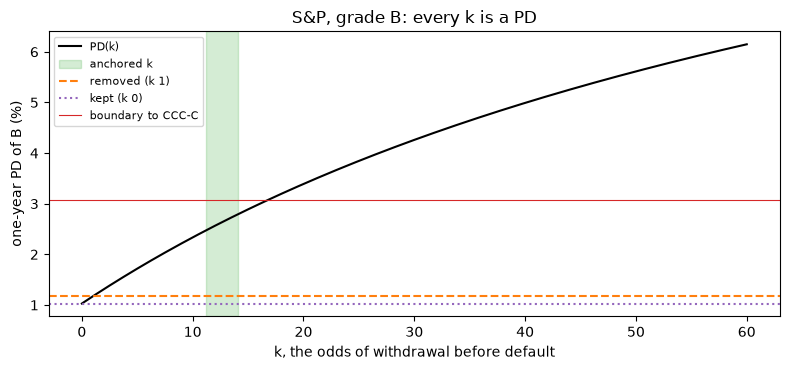

In [5]:
# Draw PD(k) with the two CEREP treatments, the anchored band and the boundary to CCC-C
grid = np.linspace(0, 60, 241)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(grid, [100 * wd.withdrawal_pd([d], [s], [w], k)[0] for k in grid], color="black", label="PD(k)")
ax.axvspan(an["k_low"][0], an["k_high"][0], color="tab:green", alpha=0.2, label="anchored k")
ax.axhline(100 * res["pd_industry"][0], color="tab:orange", linestyle="--", label="removed (k 1)")
ax.axhline(100 * res["pd_unfollowed"][0], color="tab:purple", linestyle=":", label="kept (k 0)")
ax.axhline(100 * threshold, color="tab:red", linewidth=0.8, label="boundary to CCC-C")
ax.set_xlabel("k, the odds of withdrawal before default")
ax.set_ylabel("one-year PD of B (%)")
ax.set_title("S&P, grade B: every k is a PD")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


The black curve is every PD the transition page allows, rising from the kept treatment (dotted) through the removed one
(dashed) as $k$ grows. The green band is where the default page puts $k$; its PD sits well above both usual treatments and below the
red boundary to CCC-C, which the curve crosses only at $k$ near 17. The two usual estimates are points of the same curve, at the
left end, chosen by convention rather than by the data.

## Comparison

The methods the anchored interval is set against are the three treatments of withdrawn ratings that practice uses: removing them
(the transition page, $k = 1$), keeping them in the denominator ($k = 0$, the default page's convention for the cohort), and
following them to the year end (EBA/GL/2017/16 paragraph 76; here the oracle, because it needs the outcome of every withdrawn
rating, which no transition page has). A real cohort has no known truth, so the comparison runs the case's study,
`pipeline.cases.c04_bounds.bounds_rung`, on the EM generator of S&P's counts with withdrawal informative at $k = 9$: 200 draws,
four designs (the first-year cohort, five cohorts pooled, a second source that counts only 70 % of the defaults, and the first-year
cohort ten times larger).

In [6]:
# Run the case's study on a known truth: the EM generator of S&P's counts, withdrawal informative at k 9, 200 draws
q = np.array(family["generator"]["q"])
obligors = family["generator"]["obligors"]


def make_paths(qm, obl, years=5, **defect):
    times = tuple(float(t) for t in range(years + 1))
    return RatingPaths(qm, tuple(obl), horizon=float(years), snapshots=times, **defect)


study = bnd.bounds_rung(make_paths, q, obligors, seed=20261030, scale_seed=20261031, reps=200, informative=9.0,
                        withdrawal_rate=0.06, window=1.0)
coverage = {x["id"]: {t["id"]: t["coverage"][5]["rate"] for t in x["treatments"]} for x in study["designs"]}
print(f"true one-year PD of B: {100 * study['truth'][5]:.3f} %")
for design, row in coverage.items():
    print(f"{design:15s}", " | ".join(f"{t} {v:.3f}" for t, v in row.items()))


true one-year PD of B: 1.173 %
first_year      industry 0.840 | unfollowed 0.835 | followed 0.950 | anchored 1.000 | identified 1.000
pooled          industry 0.110 | unfollowed 0.030 | followed 0.740 | anchored 0.980 | identified 1.000
capture70       industry 0.840 | unfollowed 0.835 | followed 0.950 | anchored 0.995 | identified 1.000
first_year_x10  industry 0.215 | unfollowed 0.075 | followed 0.935 | anchored 1.000 | identified 1.000


In the first-year cohort the removed and kept intervals still cover the true PD of B, 1.173 %, in 84 % and 83.5 % of the
draws: the cohort is small enough that the sampling interval is wide. Pooling five cohorts narrows the intervals around the wrong
value, and they cover 11 % and 3 %; ten times the cohort does the same, 21.5 % and 7.5 %. The anchored interval covers 100 % of
the draws in the first-year cohort and 98 % pooled. The figure shows the four designs side by side.

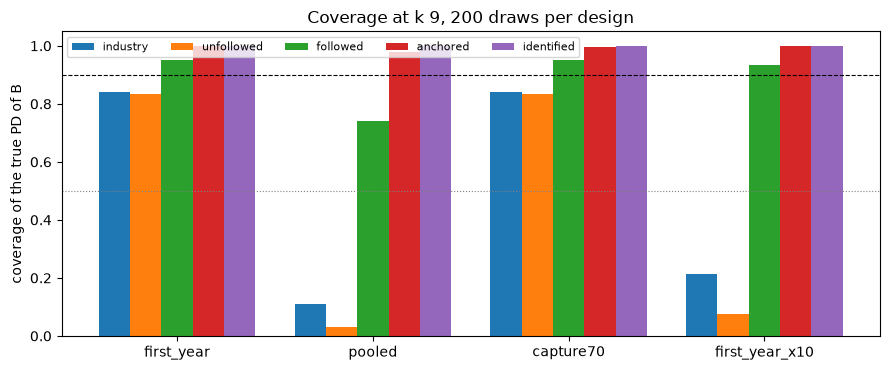

In [7]:
# Draw the coverage of the true PD of B by treatment in the four designs, with the 90 % fixed before the run
treatments = ("industry", "unfollowed", "followed", "anchored", "identified")
designs = list(coverage)
x = np.arange(len(designs))
fig, ax = plt.subplots(figsize=(9, 3.8))
for j, t in enumerate(treatments):
    ax.bar(x + (j - 2) * 0.16, [coverage[dsg][t] for dsg in designs], 0.16, label=t)
ax.axhline(0.9, color="black", linestyle="--", linewidth=0.8)
ax.axhline(0.5, color="grey", linestyle=":", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(designs)
ax.set_ylabel("coverage of the true PD of B")
ax.set_title("Coverage at k 9, 200 draws per design")
ax.legend(fontsize=8, ncol=5)
fig.tight_layout()
plt.show()


The dashed line is the 90 % the claim asks of the anchored interval, the dotted one the 50 % under which the claim expects the
existing treatments to fall. The anchored bars stand above 90 % in every design, the identified band (from $k = 0$ to Manski's bound)
covers everything but says little, and the followed oracle stays between 74 % and 95 %. The removed and kept bars fall under 50 %
only where the sample is large enough for the bias to outgrow the noise: pooled and ten times larger.

## Evidence

The claim, fixed in the SDD before any run, has three parts: the anchored interval covers the true PD of B in at least 90 % of the
draws at $k$ 1, 3 and 9; the existing treatments cover it in under 50 % at $k = 9$; and the anchored $k$ of the real cohorts is
stable, meaning at least 80 % of the annual cohorts' bands contain the pooled $k$. The study above speaks to the first two. The next
cell tests the third on S&P's real cohorts of grade B with the engine, one band per year.

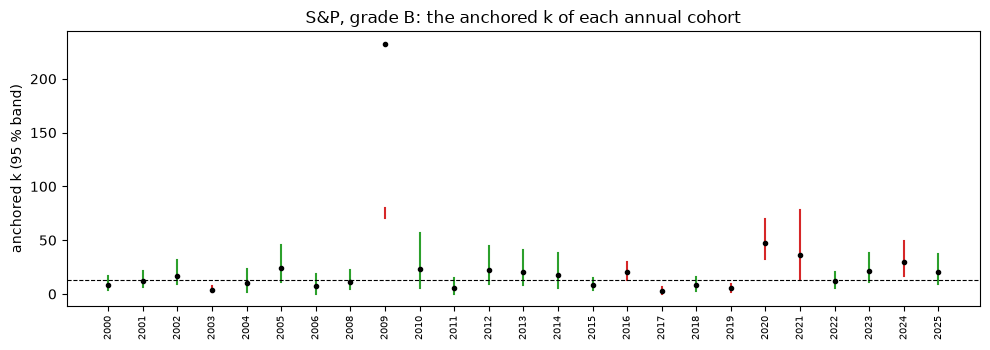

cohorts whose band holds the pooled k: 17 / 25 = 0.68


In [8]:
# Measure the stability of the anchored k: each S&P annual cohort's band for B, against the pooled k
pooled_k = an["k"][0]
bands = []
for c in b["cohorts"]:
    r = wd.withdrawal_bounds([[c["survivors"], c["defaults"]], [0.0, 0.0]], [c["withdrawn"], 0.0],
                             anchor_defaults=[c["anchor_defaults"]], anchor_obligors=[c["anchor_cohort"]], level=0.95)
    lo, mid, hi = (float(r["anchor"][key][0]) for key in ("k_low", "k", "k_high"))
    if r["reason"][0] == "ok" and np.isfinite(lo) and not np.isnan(hi):
        bands.append((c["label"], lo, mid, hi))
inside = sum(lo <= pooled_k <= hi for _, lo, _, hi in bands)
fig, ax = plt.subplots(figsize=(10, 3.6))
for i, (_, lo, mid, hi) in enumerate(bands):
    ax.plot([i, i], [lo, min(hi, 80)], color="tab:green" if lo <= pooled_k <= hi else "tab:red")
    ax.plot(i, mid, "o", color="black", markersize=3)
ax.axhline(pooled_k, color="black", linestyle="--", linewidth=0.8)
ax.set_xticks(range(len(bands)))
ax.set_xticklabels([label for label, *_ in bands], rotation=90, fontsize=7)
ax.set_ylabel("anchored k (95 % band)")
ax.set_title("S&P, grade B: the anchored k of each annual cohort")
fig.tight_layout()
plt.show()
print(f"cohorts whose band holds the pooled k: {inside} / {len(bands)} = {inside / len(bands):.2f}")


Of the 25 usable annual cohorts of grade B, 17 have a band that contains the pooled anchored $k$ of 12.59: a share of 0.68,
under the 80 % the claim fixed. The red bars are the years whose band misses it: below in 2003, 2017 and 2019, above in 2009, 2016, 2020, 2021 and 2024. The
anchored $k$ absorbs everything that makes the two pages count defaults differently, not only the informativeness of withdrawals,
and that difference moves with the year. The committed verdict and the other grades follow.

In [9]:
# The case's verdict over the committed study (200 draws per design and k), and every grade's anchored k recomputed
summary = bnd.verdict(family["rungs"])["summary"]
print({key: value for key, value in summary.items()})
for agency in ("sp", "fitch"):
    doc = json.loads((C04 / f"{agency}.json").read_text(encoding="utf-8"))["outputs"]
    for g in doc["withdrawal_bounds"]["grades"]:
        st, p = g["stability"], g["pooled"]
        if st and st["usable_cohorts"]:
            matrix = [[p["survivors"], p["defaults"]], [0.0, 0.0]]
            again = wd.withdrawal_bounds(matrix, [p["withdrawn"], 0.0], anchor_defaults=[p["anchor_defaults"]],
                                         anchor_obligors=[p["anchor_cohort"]])["anchor"]["k"][0]
            share = st["cohorts_containing_pooled_k"] / st["usable_cohorts"]
            print(f"{agency:5s} {g['grade']:5s} k {again:8.2f} | {share:.2f} | stable {st['stable']}")


{'refuted': False, 'anchored_covers_90': True, 'existing_under_50': False}
sp    AA    k    17.21 | 1.00 | stable True
sp    A     k     4.99 | 1.00 | stable True
sp    BBB   k     7.94 | 0.89 | stable True
sp    BB    k     7.50 | 0.88 | stable True
sp    B     k    12.59 | 0.68 | stable False
sp    CCC-C k    36.25 | 0.64 | stable False
fitch BBB   k   139.29 | 0.50 | stable False
fitch BB    k    24.73 | 1.00 | stable True
fitch B     k    31.65 | 0.70 | stable False
fitch CCC-C k    61.24 | 0.92 | stable True


The committed study, 200 draws per design and $k$, says the same as the run above: the anchored interval covers at least
90 % everywhere, the existing treatments do not all fall under 50 % (the first-year cohort keeps them above it), and the coverage
part of the claim is not refuted. The stability part is: at S&P the anchored $k$ is stable for AA, A, BBB and BB and not for B and
CCC-C; at Fitch it is stable for BB and CCC-C and not for BBB and B. So the anchored $k$ is a $k$ conditional on the two pages
defining default alike, which ESMA does not guarantee, and not an estimate of how informative withdrawals are.

## Results

**Answer:** The usual PD of grade B is a choice of $k$, and on S&P's pooled counts the choice moves it from 1.029 % (kept) and 1.173 %
(removed) to 13.34 % (Manski's bound). The default page anchors $k$ at 12.59 and the PD at 2.629 %, more than twice the usual figure.
On a known truth with $k = 9$ the anchored interval covers the true PD in 100 % of 200 draws of the first-year cohort and 98 % pooled,
where the removed and kept treatments cover 11 % and 3 % pooled. On the real cohorts the anchored $k$ of B holds in only 17 of 25
years, so it cannot be read as a stable property of the agency's withdrawals.

## Summary

- Every treatment of withdrawn ratings is a value of $k$ in $\mathrm{PD}(k) = (D + X(k))/N$; the transition page alone cannot
  choose among them.
- A second count of the same defaults anchors $k$; on S&P's grade B it gives $k$ 12.59 and a PD of 2.629 %.
- On a known truth the anchored interval keeps its coverage where removing or keeping the withdrawals loses it.
- The anchored $k$ moves from year to year (17 of 25 cohorts of B hold the pooled value), because it absorbs the difference
  between the two pages' definitions of default.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Manski, C. F. (1989), Anatomy of the selection problem, Journal of Human Resources 24(3). https://doi.org/10.2307/145818
- European Banking Authority (2017), Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures, EBA/GL/2017/16, paragraph 76.
- riskvalidation 1.1.0, `transitions.withdrawals` and its page. https://github.com/fsantibanezleal/CAOS_RiskValidation/blob/main/docs/transitions/06_withdrawal-bounds.md